# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


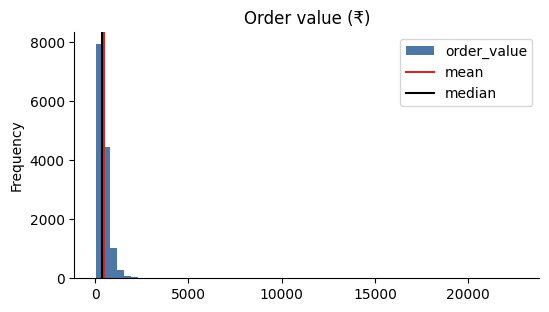

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

**(a)** Insight 2 is numerically correct only if “average” means the mean: the mean order value is about ₹465, but the median is ₹358 and the distribution is strongly right-skewed (skew ≈ 13.2). I would report both, because a small number of very large orders pull the mean upward; the mean alone does not describe a typical order. **(b)** About 27.6% of ratings are missing overall, and missingness is especially high in Hyderabad (45.0%). The delivery-time/rating correlation therefore describes rated orders only and may be biased if customers who do not rate differ systematically from those who do.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

In [5]:
multimodal_supported = False
best_bin_width = 4

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

Before accepting a shape claim, compare several sensible bin widths and inspect the underlying observations, because a narrow bin can create apparent peaks while a wide bin can hide them.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


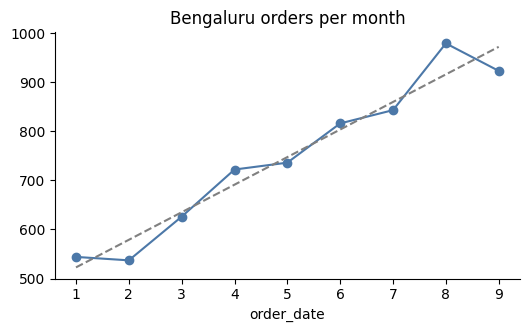

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


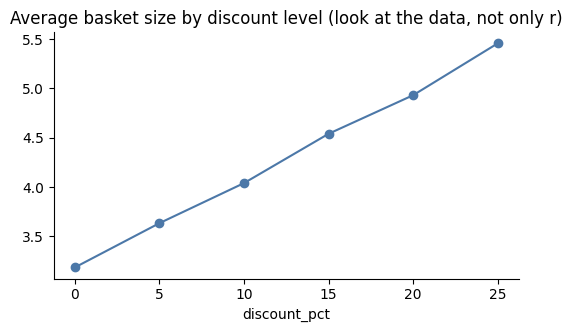

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

**(a)** The overall upward trend is reasonable, but “grew steadily” is inaccurate: orders dip from January to February and again from August to September. Bengaluru rises from 544 orders in January to 923 in September, with a fitted slope of about 56.2 orders per month (Kendall τ ≈ 0.89, p ≈ 0.0002); I would show the monthly points and fitted trend, not describe the path as monotonic or treat it as a forecast. **(b)** The discount–items correlation is positive (r ≈ 0.38), and the grouped chart can show how average basket size varies by discount level. It does not establish that discounts cause larger baskets: promotions may be targeted to particular customers or order types, and other factors may affect both. **(c)** The discount–loyalty-points pair (r ≈ −0.02) is the clearest likely false alarm: the effect is practically negligible despite its small p-value, and 21 pairwise tests create a multiple-comparisons risk (about 1.05 false positives expected at α = 0.05 if all nulls were true).

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

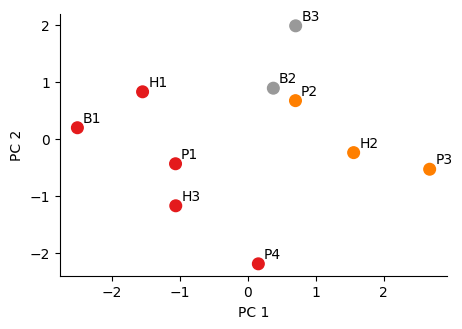

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [9]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

With only 10 stores, each store can strongly influence the clusters, so the apparent groups may not generalise and K-means will create three groups even if three natural types do not exist. Before naming them, I would inspect the original features and store-level values, check whether the groups are stable under different scaling and k choices, and validate the segments with operational knowledge or more stores.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [10]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month.loc[9] - hyd_month.loc[8]) / hyd_month.loc[8] * 100
first_test = "B"  # Check for missing store-week rows before attributing the decline to service or promotions.

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [11]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.loc[9] - ontime.loc[8]
culprit_store = "H2"

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

The data support a real September order decline, but they also reveal missing weekly records for Hyderabad store H2, so the data-completeness hypothesis is supported. On-time performance fell only slightly, from about 89.0% in August to 88.7% in September (−0.3 percentage points), which does not establish that service caused the 28.4% order decline; the competitor explanation cannot be tested with this dataset. **Corrected insight 4:** “Recorded Hyderabad orders fell 28.4% from August to September; H2 has missing weekly records, while the on-time rate changed by only about −0.3 percentage points, so the decline should not be attributed to worse delivery service without further investigation.”

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [12]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() - old[2].sum()) / old[2].sum() * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

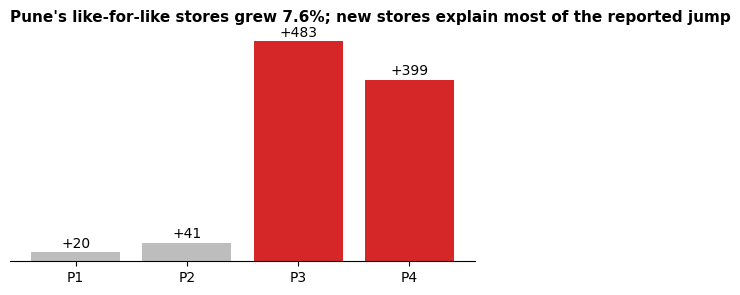

In [13]:
title = "Pune's like-for-like stores grew 7.6%; new stores explain most of the reported jump"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [14]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\\n", overall, "\\n\\nShare of each partner's orders by zone (%):\\n", mix)

by_zone = (df.groupby(["zone", "delivery_partner"])["on_time"].mean().unstack() * 100).round(1)
better_in_every_zone = "Partner A"
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:\n delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 \n\nShare of each partner's orders by zone (%):\n zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

**(a)** Pune did not more than double on a like-for-like basis: P1 and P2 together grew only about 7.6% from Q2 to Q3. Total orders rose much more because P3 and P4 were new stores operating in Q3, so the comparison mixes expansion with growth at existing stores. **(b)** Partner B handles a much larger share of Urban orders, which are easier to deliver on time; Partner A handles most Suburban orders. Within both zones Partner A has the higher on-time rate, so this is a form of Simpson's paradox. Before accepting the overall comparison, ask: “Are we comparing partners on a like-for-like mix of zones, distances and order difficulty?”

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [15]:
decisions = {
    1: "Correct",  # overall trend is upward, but month-to-month growth is not steady
    2: "Correct",  # mean is correct but hides the skew and median
    3: "Correct",  # like-for-like growth is modest; new stores drive total increase
    4: "Correct",  # decline is real, but the causal explanation is unsupported
    5: "Correct",  # overall mix reverses the within-zone comparison
    6: "Accept",   # correlation matches the rated-order subset
    7: "Accept",   # positive association, not a causal claim
    8: "Accept",   # suburban delivery is about five minutes slower
    9: "Reject",   # no October data or forecasting evidence
}

analysts_true_insights = 7    # expert-team benchmark supplied by the activity
accepted = sum(v == "Accept" for v in decisions.values())
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine insights with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 3/9 | precision = 0.33 | recall = 0.43 | F1 = 0.38
Review effort spent on insights that were not fully correct: 67%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

I would treat this AI as an assistant, not a replacement: only four of its nine statements are acceptable as written, while the rest need correction or rejection. It can surface useful patterns quickly, but a human must check data quality, comparison groups and causal claims before the report is presented.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [16]:
levels = {
    2: "data",
    6: "between",
    9: "beyond",
}      # data = what is plotted; between = relationship; beyond = prediction/causal explanation
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [17]:
user_actions = {
    '"Never use pie charts in this report"': "Reject",
    '"Use 5-minute bins for delivery time"': "Constrain",
    '"Focus on on-time rate by city"': "Steer",
    '"Keep the like-for-like Pune chart on the dashboard"': "Pin",
    '"Not this chart again"': "Adjust",
}
user_actions

{'"Never use pie charts in this report"': 'Reject',
 '"Use 5-minute bins for delivery time"': 'Constrain',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Adjust'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [18]:
threat = "wrong problem"   # The calculations may be correct, but they answer a different question.
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

**Insight 2:** “The mean order value is ₹465, while the median is ₹358; the strong right skew means the mean is pulled upward by a small number of high-value orders.” **Insight 4:** “Recorded Hyderabad orders declined 28.4% from August to September. H2 has missing weekly records, and the on-time rate changed by only −0.3 percentage points, so the available data do not show that worsening delivery service caused the decline.”

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

**1. Automation bias.** The Partner B comparison initially looks convincing because the percentages are clear and the overall gap is large. I might have accepted the recommendation without checking the zone mix; the within-zone table changes the conclusion.

**2. Choosing the level of automation.** I would let the AI automate routine summaries such as monthly order counts and basic chart generation, because these are easy to verify and redo. I would require a human check for recommendations that change partner allocation or explain customer behaviour, because the operational and financial consequences are higher.

**3. Making trust cheaper.** For Hyderabad, the tool should display store-by-week row counts, missing periods and the on-time comparison next to the order trend. I would want a drill-down to the source rows and an option to correct or annotate the data before the insight is approved.

**4. Responsibility.** The person signing off and presenting the report remains accountable for checking it, while the vendor is responsible for the tool's documented limitations and defects. Next time I would keep a reproducible validation record, state uncertainty and data gaps, and have Meera review the final wording before presenting.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

**1. Automation bias.** The Partner B comparison initially looks convincing because the percentages are clear and the overall gap is large. I might have accepted the recommendation without checking the zone mix; the within-zone table changes the conclusion.

**2. Choosing the level of automation.** I would let the AI automate routine summaries such as monthly order counts and basic chart generation, because these are easy to verify and redo. I would require a human check for recommendations that change partner allocation or explain customer behaviour, because the operational and financial consequences are higher.

**3. Making trust cheaper.** For Hyderabad, the tool should display store-by-week row counts, missing periods and the on-time comparison next to the order trend. I would want a drill-down to the source rows and an option to correct or annotate the data before the insight is approved.

**4. Responsibility.** The person signing off and presenting the report remains accountable for checking it, while the vendor is responsible for the tool's documented limitations and defects. Next time I would keep a reproducible validation record, state uncertainty and data gaps, and have Meera review the final wording before presenting.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

**1. Automation bias.** The Partner B comparison initially looks convincing because the percentages are clear and the overall gap is large. I might have accepted the recommendation without checking the zone mix; the within-zone table changes the conclusion.

**2. Choosing the level of automation.** I would let the AI automate routine summaries such as monthly order counts and basic chart generation, because these are easy to verify and redo. I would require a human check for recommendations that change partner allocation or explain customer behaviour, because the operational and financial consequences are higher.

**3. Making trust cheaper.** For Hyderabad, the tool should display store-by-week row counts, missing periods and the on-time comparison next to the order trend. I would want a drill-down to the source rows and an option to correct or annotate the data before the insight is approved.

**4. Responsibility.** The person signing off and presenting the report remains accountable for checking it, while the vendor is responsible for the tool's documented limitations and defects. Next time I would keep a reproducible validation record, state uncertainty and data gaps, and have Meera review the final wording before presenting.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

**1. Automation bias.** The Partner B comparison initially looks convincing because the percentages are clear and the overall gap is large. I might have accepted the recommendation without checking the zone mix; the within-zone table changes the conclusion.

**2. Choosing the level of automation.** I would let the AI automate routine summaries such as monthly order counts and basic chart generation, because these are easy to verify and redo. I would require a human check for recommendations that change partner allocation or explain customer behaviour, because the operational and financial consequences are higher.

**3. Making trust cheaper.** For Hyderabad, the tool should display store-by-week row counts, missing periods and the on-time comparison next to the order trend. I would want a drill-down to the source rows and an option to correct or annotate the data before the insight is approved.

**4. Responsibility.** The person signing off and presenting the report remains accountable for checking it, while the vendor is responsible for the tool's documented limitations and defects. Next time I would keep a reproducible validation record, state uncertainty and data gaps, and have Meera review the final wording before presenting.